In [ ]:
Retail Sales EDA Project

# Exploratory Data Analysis on Retail Sales Data
## Project Objective
To analyze retail sales data, understand customer
purchasing patterns, identify sales trends, and
provide actionable business recommendations.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib 
- Seaborn
- Jupyter Notebook

## Dataset
Retail Sales Dataset from Kaggle



In [ ]:
%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Import libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("Pandas version:", pd.__version__)
print("All libraries imported successfully!")

Pandas version: 3.0.6
All libraries imported successfully!


Initial inspection — shape, data types, missing values

In [ ]:
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df.info()

Rows and columns: (9000, 16)

Column names:
['order_id', 'order_date', 'customer_id', 'gender', 'age', 'region', 'segment', 'category', 'sub_category', 'product_name', 'unit_price', 'quantity', 'discount', 'sales', 'profit', 'ship_mode']

Data types:
order_id            str
order_date          str
customer_id         str
gender              str
age             float64
region              str
segment             str
category            str
sub_category        str
product_name        str
unit_price      float64
quantity          int64
discount        float64
sales           float64
profit          float64
ship_mode           str
dtype: object

Missing values:
order_id          0
order_date        0
customer_id       0
gender           54
age             108
region            0
segment           0
category          0
sub_category      0
product_name      0
unit_price        0
quantity          0
discount          0
sales             0
profit            0
ship_mode        36
dtype: int64



Observation: The dataset contains retail order information, customer demographics, product details, sales, and profit. The shape, data types, missing values, and duplicate count were checked before further analysis.

3. Data cleaning

In [ ]:
df = df.copy()

# Convert date
df["order_date"] = pd.to_datetime(
    df["order_date"], errors="coerce"
)

# Convert numerical columns
numeric_cols = [
    "age", "unit_price", "quantity",
    "discount", "sales", "profit"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

rows_before = len(df)

df = df.drop_duplicates().copy()

required_cols = [
    "order_date", "gender", "age", "category",
    "product_name", "quantity", "unit_price",
    "sales", "profit"
]

df = df.dropna(subset=required_cols).copy()

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))
print("Rows removed:", rows_before - len(df))
print("\nMissing values after cleaning:")
print(df[required_cols].isnull().sum())

Rows before cleaning: 9000
Rows after cleaning: 8839
Rows removed: 161

Missing values after cleaning:
order_date      0
gender          0
age             0
category        0
product_name    0
quantity        0
unit_price      0
sales           0
profit          0
dtype: int64


4. Descriptive statistics

In [ ]:
print(df.shape)
print(df.dtypes)
print(df.columns.tolist())

In [ ]:
import pandas as pd
from IPython.display import display

# Select numeric columns
num_df = df.select_dtypes(include="number")

print("Numeric columns:", num_df.columns.tolist())

if num_df.empty:
    print("No numeric columns found. Please check the data types.")
else:
    stats = pd.DataFrame({
        "Mean": num_df.mean(),
        "Median": num_df.median(),
        "Mode": num_df.mode().iloc[0],
        "Standard Deviation": num_df.std()
    })

    display(stats.round(2))

In [ ]:
num_df = df.select_dtypes(include="number")

stats = pd.DataFrame({
    "Mean": num_df.mean(),
    "Median": num_df.median(),
    "Mode": num_df.mode().iloc[0],
    "Standard Deviation": num_df.std()
})

display(stats.round(2))

Observation: Mean and median describe the typical values of numerical variables. Standard deviation shows how much values vary. Mode identifies the most frequently occurring value. Interpret these statistics according to each column's meaning

5. Monthly sales trend

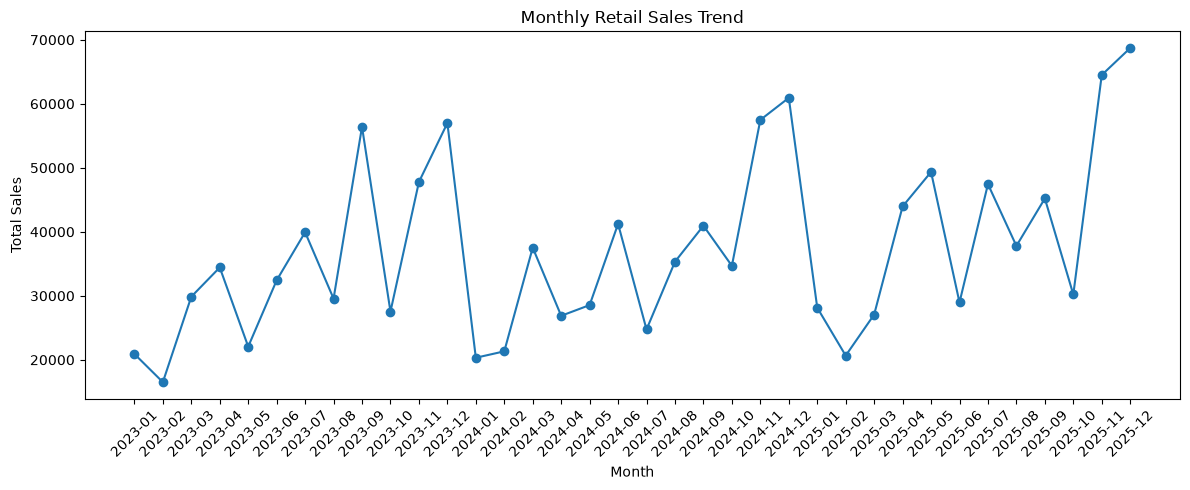

Highest sales month: 2025-12
Lowest sales month: 2023-02


In [33]:
df["month"] = df["order_date"].dt.to_period("M")

monthly_sales = (
    df.groupby("month")["sales"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)
plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Highest sales month:", monthly_sales.idxmax())
print("Lowest sales month:", monthly_sales.idxmin())

Monthly sales varied over the period. The highest-sales month was [Highest sales month: 2025-12], while the lowest-sales month was [Lowest sales month: 2023-02]. Investigate possible seasonal demand, promotions, or changes in order volume before deciding on inventory levels

6. Quarterly sales trend

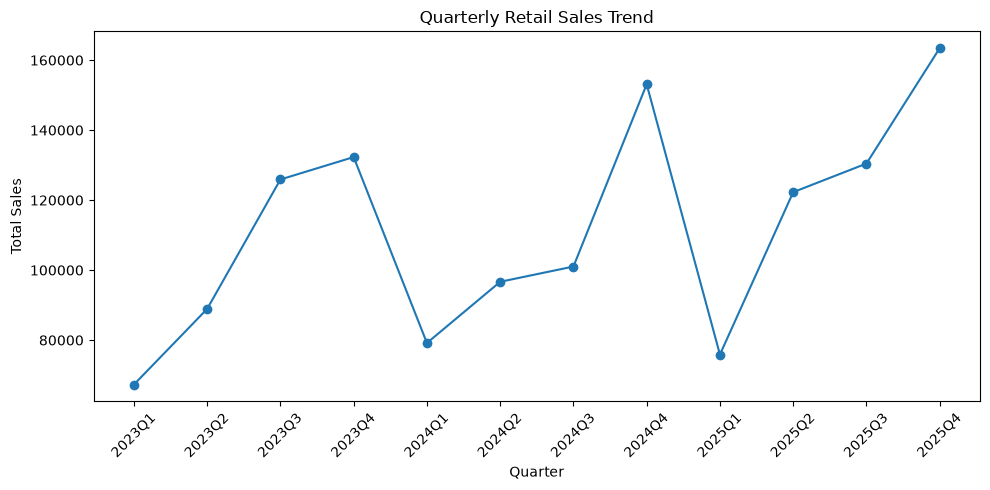

quarter
2023Q1     67288.69
2023Q2     88912.61
2023Q3    125897.83
2023Q4    132304.36
2024Q1     79170.78
2024Q2     96663.94
2024Q3    101022.66
2024Q4    153100.88
2025Q1     75868.54
2025Q2    122277.79
2025Q3    130451.55
2025Q4    163426.08
Freq: Q-DEC, Name: sales, dtype: float64

In [34]:
df["quarter"] = df["order_date"].dt.to_period("Q")

quarterly_sales = (
    df.groupby("quarter")["sales"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(10, 5))
plt.plot(
    quarterly_sales.index.astype(str),
    quarterly_sales.values,
    marker="o"
)
plt.title("Quarterly Retail Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(quarterly_sales)

Observation: Quarterly sales help compare performance across three-month periods. Identify the strongest and weakest quarters from the displayed results and investigate the reasons using product and customer data.

Customer age-group distribution

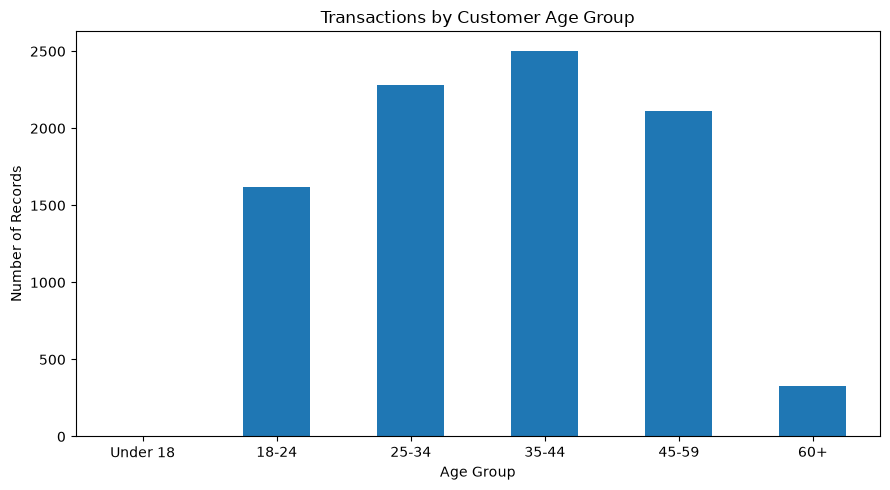

age_group
Under 18       0
18-24       1618
25-34       2278
35-44       2504
45-59       2114
60+          325
Name: count, dtype: int64

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 18, 25, 35, 45, 60, np.inf],
    labels=[
        "Under 18", "18-24", "25-34",
        "35-44", "45-59", "60+"
    ],
    right=False
)

age_counts = df["age_group"].value_counts(sort=False)

age_counts.plot(kind="bar", figsize=(9, 5))
plt.title("Transactions by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(age_counts)

8. Gender distribution

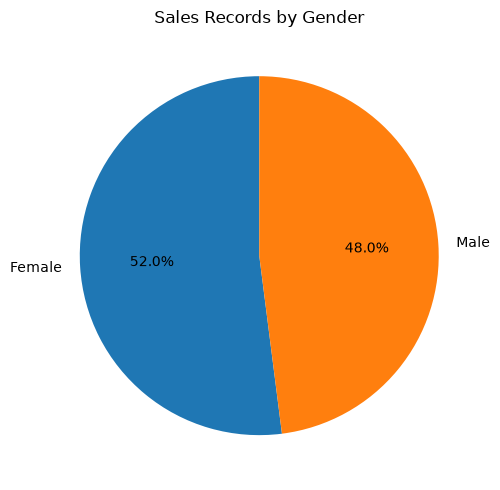

gender
Female    4598
Male      4241
Name: count, dtype: int64

In [38]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(7, 5))
plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Sales Records by Gender")
plt.ylabel("")
plt.tight_layout()
plt.show()

display(gender_counts)

Observation: The chart shows the proportion of records for each gender. Use the actual percentages to compare representation; do not assume that a larger share automatically means higher profitability.

9. Top 10 best-selling products

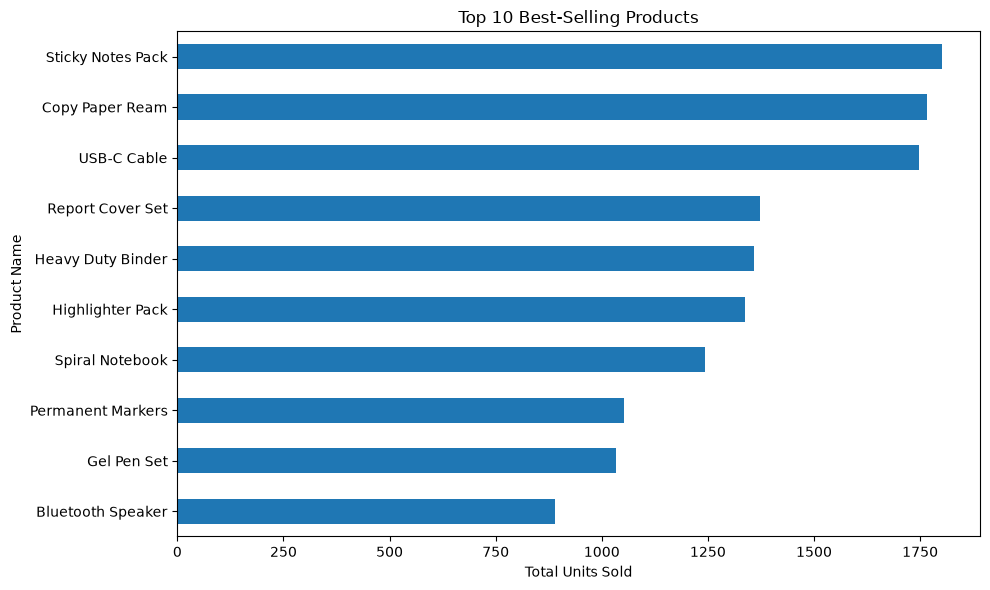

product_name
Sticky Notes Pack    1801
Copy Paper Ream      1767
USB-C Cable          1747
Report Cover Set     1372
Heavy Duty Binder    1359
Highlighter Pack     1337
Spiral Notebook      1242
Permanent Markers    1052
Gel Pen Set          1033
Bluetooth Speaker     889
Name: quantity, dtype: int64

In [39]:
top_products = (
    df.groupby("product_name")["quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products.sort_values().plot(
    kind="barh", figsize=(10, 6)
)
plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Units Sold")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

display(top_products)

Observation: The chart identifies the products with the highest total units sold. These products may need closer inventory monitoring. Sales quantity alone does not show which products earn the most profit.

10. Revenue by product category

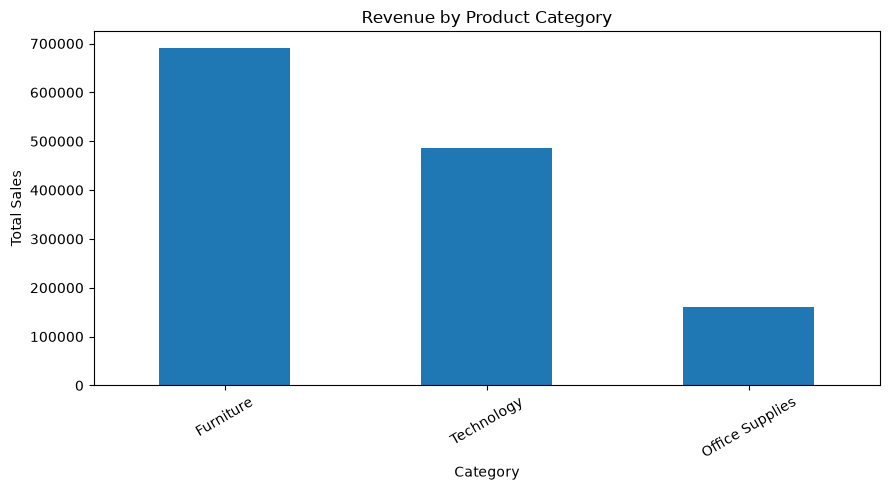

category
Furniture          690508.06
Technology         485803.97
Office Supplies    160073.68
Name: sales, dtype: float64

In [40]:
category_sales = (
    df.groupby("category")["sales"]
    .sum()
    .sort_values(ascending=False)
)

category_sales.plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(category_sales)

11. Correlation heatmap

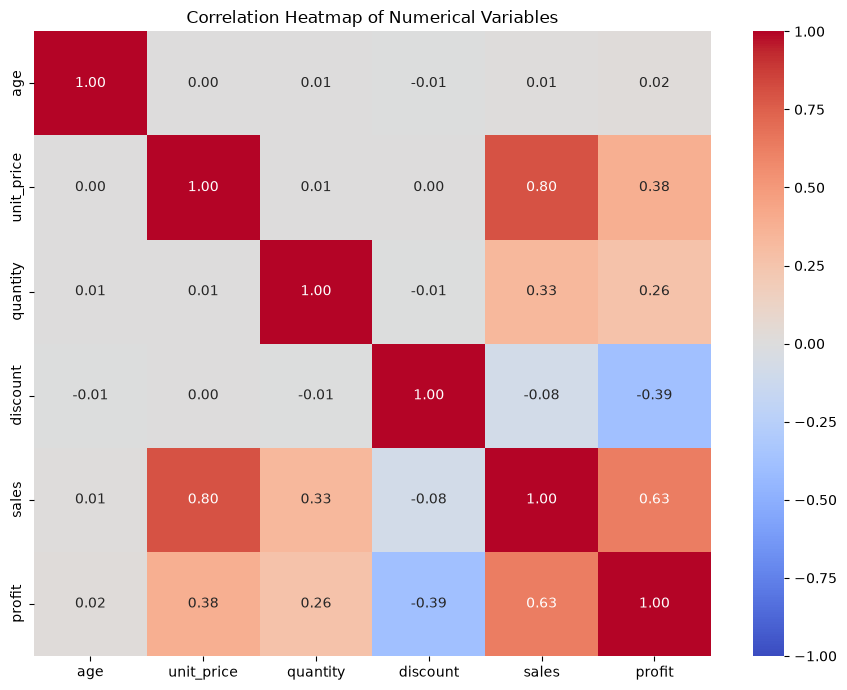

,age,unit_price,quantity,discount,sales,profit
age,1.00,0.00,0.01,-0.01,0.01,0.02
unit_price,0.00,1.00,0.01,0.00,0.80,0.38
quantity,0.01,0.01,1.00,-0.01,0.33,0.26
discount,-0.01,0.00,-0.01,1.00,-0.08,-0.39
sales,0.01,0.80,0.33,-0.08,1.00,0.63
profit,0.02,0.38,0.26,-0.39,0.63,1.00


In [41]:
corr_cols = [
    "age", "unit_price", "quantity",
    "discount", "sales", "profit"
]

correlation_matrix = df[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

display(correlation_matrix.round(2))

Observation: Correlation values near +1 indicate a strong positive linear relationship; values near -1 indicate a strong negative linear relationship; values near 0 indicate a weak linear relationship. Correlation does not establish causation.

12. Additional visualization: sales versus profit

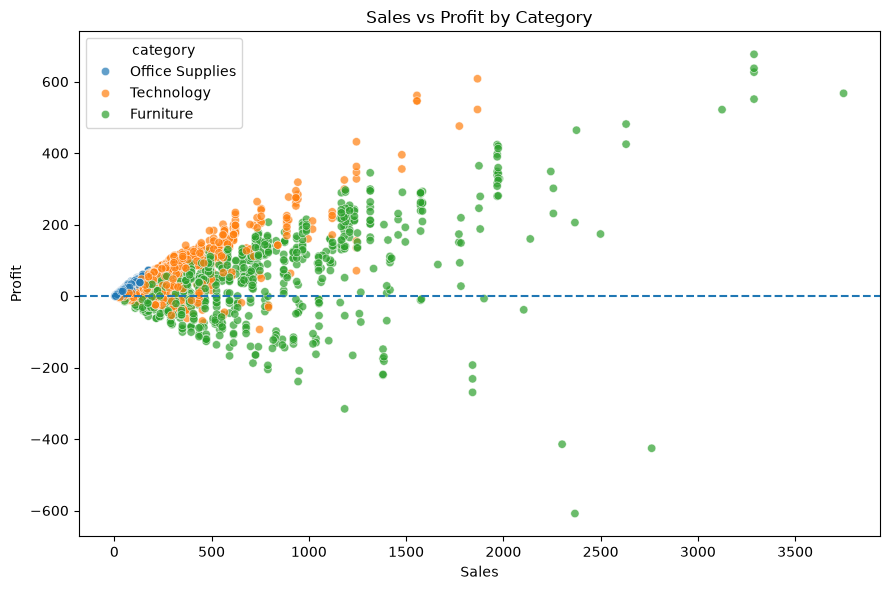

In [42]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="sales",
    y="profit",
    hue="category",
    alpha=0.7
)
plt.axhline(0, linestyle="--")
plt.title("Sales vs Profit by Category")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

Observation: Examine points with high sales but low or negative profit. Review discount levels, product costs, and other relevant factors before recommending changes. A scatterplot can highlight records for investigation but does not explain their causes by itself.

13. Key findings

In [43]:
print("Total sales:", round(df["sales"].sum(), 2))
print("Total profit:", round(df["profit"].sum(), 2))
print("Total units sold:", df["quantity"].sum())
print("Average order-record sales:", round(df["sales"].mean(), 2))

print("Highest sales month:", monthly_sales.idxmax())
print("Highest sales quarter:", quarterly_sales.idxmax())
print("Top sales category:", category_sales.idxmax())
print("Top-selling product:", top_products.index[0])
print("Largest age group:", age_counts.idxmax())
print("Most frequent gender:", gender_counts.idxmax())

Total sales: 1336385.71
Total profit: 199540.85
Total units sold: 20175
Average order-record sales: 151.19
Highest sales month: 2025-12
Highest sales quarter: 2025Q4
Top sales category: Furniture
Top-selling product: Sticky Notes Pack
Largest age group: 35-44
Most frequent gender: Female
